In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [4]:
frequency_table = df['category'].value_counts()

In [ ]:
top_5_products = df['category'].value_counts().head(5)
top_5_products

<Axes: xlabel='category'>

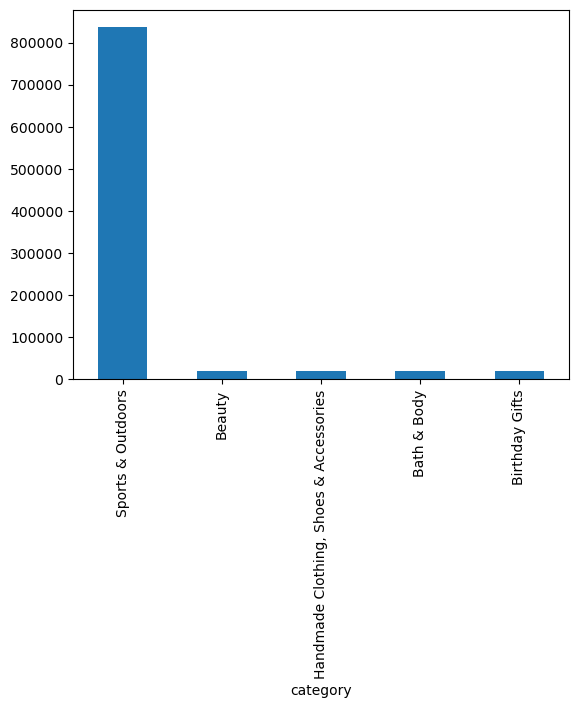

In [8]:
top_5_products.plot(kind='bar')

In [ ]:
top_5_normalized = df['category'].value_counts(normalize=True).head(5)


<Axes: ylabel='proportion'>

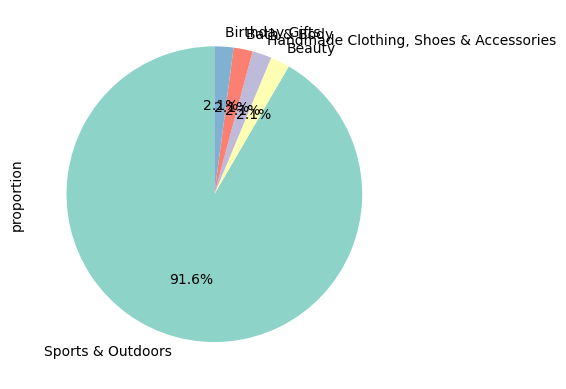

In [ ]:
df['category'].value_counts(normalize=True).head(5).plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))



# Sports & Outdoors dominate the category distribution
# Sports & Outdoors is clearly the most popular category in this dataset.
# Significantly high variability in prices as indicated by standard deviation, range, and variance.
# IQR suggests presence of outliers.

In [31]:
# The mode is significantly lower than the mean, indicating a right-skewed distribution.

mean = df['price'].mean()
mode = df['price'].mode()
median = df['price'].median()

mean, mode, standard_deviation

(np.float64(89.24380943923663),
 0    9.99
 Name: price, dtype: float64,
 345.6088617535223)

In [ ]:


standard_deviation = df['price'].std()
variance = df['price'].var()
range = df['price'].max() - df['price'].min()
quartiles_price = df['price'].quantile([0.25, 0.5, 0.75])
interquartile_range = quartiles_price[0.75] - quartiles_price[0.25]

standard_deviation, variance, range, interquartile_range

(345.6088617535223, 119445.4853225653, 100000.0, np.float64(36.0))

<Axes: ylabel='Frequency'>

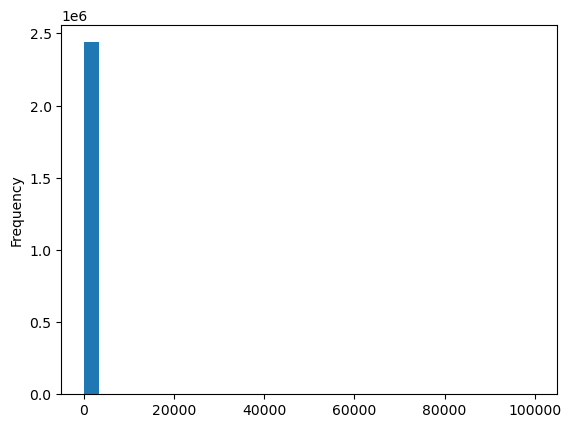

In [63]:
df['price'].plot.hist(bins=30)

In [ ]:
bins = pd.qcut(df['price'], q=10)
bins.value_counts().sort_index()

# Around 90% of products are priced between 0 and 149.99. The remaining 10% priced up to 100,000, with potential outliers skewing the distribution.


price
(-0.001, 5.99]        248384
(5.99, 8.99]          274038
(8.99, 11.77]         210961
(11.77, 14.99]        271608
(14.99, 19.09]        217276
(19.09, 25.49]        245882
(25.49, 36.0]         242540
(36.0, 60.49]         244280
(60.49, 149.99]       245180
(149.99, 100000.0]    243502
Name: count, dtype: int64

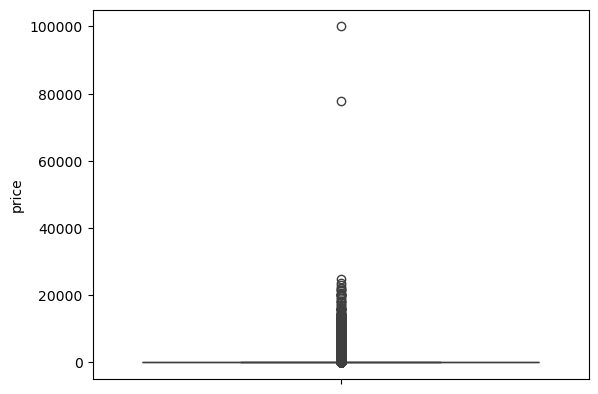

In [ ]:
sns.boxplot(y=df['price'])
plt.show()

In [ ]:
rating_mean = df['stars'].mean()
rating_mode = df['stars'].mode()
rating_median = df['stars'].median()

rating_mean, rating_mode, rating_median

# The majority of customers do not rate products, as indicated by the mode of 0.

(np.float64(2.152836472966065),
 0    0.0
 Name: stars, dtype: float64,
 0.0)

In [ ]:
variance = df['stars'].var()
standard_deviation = df['stars'].std()  
range = df['stars'].max() - df['stars'].min()
quartiles_rating = df['stars'].quantile([0.25, 0.5, 0.75])
interquartile_range = quartiles_rating[0.75] - quartiles_rating[0.25]

variance, standard_deviation, range, interquartile_range

# There is a wide variation in ratings, with some products receiving very low ratings or none at all, while others achieving high ratings.

(4.81743402976196, 2.1948653785054697, 5.0, np.float64(4.4))

In [ ]:
rating_skewness = df['stars'].skew()
rating_kurtosis = df['stars'].kurtosis()

rating_skewness, rating_kurtosis


# Ratings kurtosis is negative, suggesting a flatter distribution with fatter tails.
# Rartings are slightly positive skewed, indicating a longer tail on the right side of the distribution.

(np.float64(0.08120735761080985), np.float64(-1.9260061280432985))

<Axes: ylabel='Frequency'>

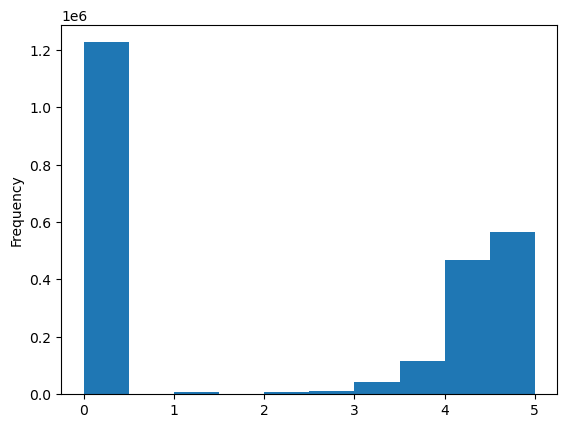

In [ ]:
df['stars'].plot.hist(bins=10)

# customers tend to either not rate products at all, or give them high ratings (between 4 and 5 stars), while 1 to 4 stars are less common.
